# Retention Decision Optimization with Pyomo and Gurobi

A completed portfolio extension using a 750-user identifier-hash sample from the later KKBOX cohort. Predictions come from the existing historical-trained logistic regression specification. Intervention effects, costs, margins, budgets, capacity, and eligibility are hypothetical. No retention intervention was delivered.

This notebook reviews saved results. The complete model and reproduction workflow are in `scripts/retention_optimization.py` and `docs/retention_optimization.md`.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
REPORTS = ROOT / "reports" / "optimization"
config = json.loads((REPORTS / "config.json").read_text())
summary = pd.read_csv(REPORTS / "strategy_summary.csv")
solver_results = pd.read_csv(REPORTS / "solver_results.csv")
config["prediction_quality"]

{'historical_training_users': 882127,
 'later_evaluation_users': 970960,
 'later_log_loss': 0.20731011815003084,
 'later_roc_auc': 0.8498934594251156,
 'independent_test': False}

## Model

For user $i$ and action $a$ (reminder or discount), $x_{ia}\in\{0,1\}$. Both variables zero means no contact.

Base-assumption objective: $\max\sum_{i,a}x_{ia}(V_i\Delta_{ia}-c_a)$.

Constraints: $\sum_a x_{ia}\le1$ for each user; $\sum_{i,a}c_a x_{ia}\le B$; $\sum_i x_{ia}\le K_a$ for each channel.

The robust formulation maximizes a floor $z$, with $z\le\sum_{i,a}x_{ia}(V_i\Delta_{ias}-c_a)$ for every scenario $s$. These are single-stage robust decisions, not multistage stochastic programming.

Predicted churn risk is not a measured treatment effect. Uplift is simulated by multiplying predicted risk by an assumed action-specific relative risk reduction. The economic assumptions are fully recorded below.

In [2]:
{key: config[key] for key in [
    "sample_rule", "costs", "capacities", "assumed_margin",
    "assumed_relative_risk_reductions", "scenario_multipliers",
    "candidate_eligibility", "value_units"
]}

{'sample_rule': 'first 750 user IDs ordered by md5(msno), msno; no labels used',
 'costs': {'reminder': 0.2, 'discount': 2.0},
 'capacities': [150, 60],
 'assumed_margin': 'Lognormal(log(100), 0.4), clipped to [30,250]',
 'assumed_relative_risk_reductions': {'reminder': '(0.04 + 0.10 * recent_recorded_days / 7) * Uniform(0.8,1.2)',
  'discount': '(0.10 + 0.20 * (1 - auto_renew_share)) * Uniform(0.8,1.2); missing share=0.5'},
 'scenario_multipliers': {'weak': [0.4, 0.3],
  'base': [1.0, 1.0],
  'strong': [1.4, 1.5]},
 'candidate_eligibility': 'assumed; no consent or active subscription verification',
 'value_units': 'hypothetical monetary units, not actual currency or observed revenue'}

## Strategy comparison

All strategies use identical users, costs, one-action constraints, channel capacities, and budgets. Risk priority processes users by descending predicted risk and prefers their highest positive base-value action. Value/cost greedy repeatedly selects the best feasible marginal net value per cost, including upgrades from reminders to discounts. Random averages 100 seeded permutations of those pairs. No intervention is always a feasible zero-value alternative.

Scenario outcomes are analytical expectations under assumed probabilities, not measured business results. Random-run variability describes allocation randomness, not uncertainty in estimated treatment effects.

In [3]:
display(summary.loc[summary.budget == 120].round(3))
display(solver_results.round(6))

,budget,strategy,runs,spend,contacted,reminders,discounts,base_net_value,weak_net_value,strong_net_value,worst_scenario_net_value,base_expected_incremental_retained,base_net_value_std
10,120,nominal_milp,1,120.0,195.0,150.0,45.0,787.160,171.937,1220.951,171.937,8.389,NaN
11,120,random,100,120.0,195.0,150.0,45.0,494.489,81.743,784.338,81.743,5.793,37.603
12,120,risk_priority,1,120.0,78.0,20.0,58.0,704.784,130.830,1113.782,130.830,7.942,NaN
13,120,robust_maximin,1,86.0,178.0,150.0,28.0,712.321,182.062,1082.916,182.062,7.260,NaN
14,120,value_per_cost,1,120.0,195.0,150.0,45.0,787.160,171.937,1220.951,171.937,8.389,NaN


,budget,strategy,termination,solve_seconds,objective,lower_bound,upper_bound,absolute_gap,binary_variables,constraints
0,30,nominal_milp,optimal,0.045897,467.180253,467.180253,467.180253,0.0,1500,753
1,30,robust_maximin,optimal,0.047215,149.173344,149.173344,149.173344,0.0,1500,756
2,60,nominal_milp,optimal,0.040891,630.161428,630.161428,630.161428,0.0,1500,753
3,60,robust_maximin,optimal,0.049357,174.192116,174.192116,174.192116,0.0,1500,756
4,120,nominal_milp,optimal,0.040385,787.159923,787.159923,787.159923,0.0,1500,753
5,120,robust_maximin,optimal,0.049480,182.061653,182.061653,182.061653,0.0,1500,756
6,200,nominal_milp,optimal,0.039040,812.103242,812.103242,812.103242,0.0,1500,753
7,200,robust_maximin,optimal,0.044639,182.061653,182.061653,182.061653,0.0,1500,756


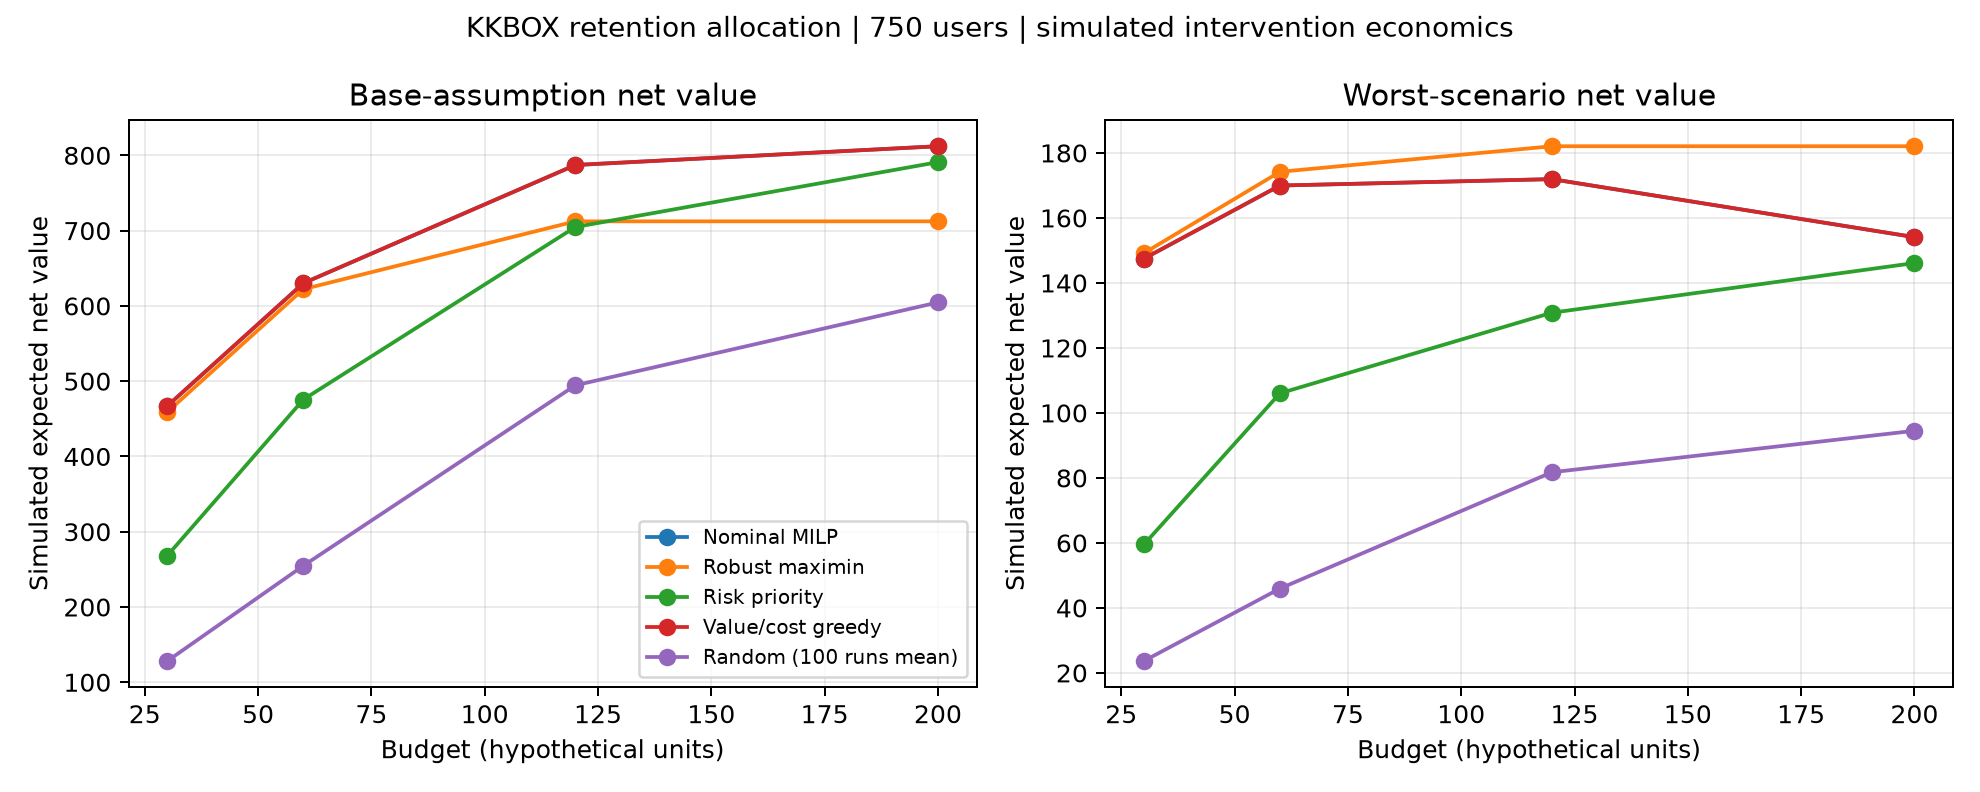

In [4]:
display(Image(filename=str(REPORTS / "budget_sensitivity.png")))

## Verification and interpretation

Both nominal and robust models are checked against exhaustive enumeration on a three-user problem. Each allocation is checked for binary decisions, no duplicate interventions, budget feasibility, and channel capacity. Nominal optima must dominate all feasible baselines under the nominal objective; robust optima must dominate nominal decisions in the worst modeled scenario. Optimal objective values must be nondecreasing with budget.

The later cohort has already been examined in earlier modeling, so it is not an untouched test. A 750-user sample meets the free size-limited Gurobi license; this is not evidence of million-user optimization scalability. User-level inputs and allocations stay in ignored local data files.

Do not claim observed churn reduction, real ROI, experimentally estimated uplift, or multistage stochastic programming.

In [5]:
display(pd.DataFrame(config["enumeration_checks"]))
print("All solver runs optimal:", solver_results.termination.eq("optimal").all())
print("Maximum absolute solver gap:", solver_results.absolute_gap.max())

,robust,enumeration_optimum,solver_optimum
0,False,8.6,8.6
1,True,5.8,5.8


All solver runs optimal: True
Maximum absolute solver gap: 0.0
